In [7]:

import math
import sys
import matplotlib
import matplotlib.pyplot as plt

HUMAN, AI = "X", "O"
LINES = [(0, 1, 2), (3, 4, 5), (6, 7, 8), (0, 3, 6), (1, 4, 7), (2, 5, 8), (0, 4, 8), (2, 4, 6)]
nodes_explored = 0

def winner_line(board):
    for line in LINES:
        a, b, c = line
        if board[a] != " " and board[a] == board[b] == board[c]:
            return board[a], line
    return None, None

def is_full(board):
    return " " not in board

def print_board(board):
    for r in range(3):
        print(" " + " | ".join(board[3 * r:3 * r + 3]))
        if r < 2:
            print("---+---+---")

def minimax(board, is_max):
    global nodes_explored
    nodes_explored += 1
    w, _ = winner_line(board)
    if w == AI:
        return 1
    if w == HUMAN:
        return -1
    if is_full(board):
        return 0
    if is_max:
        best = -math.inf
        for i in range(9):
            if board[i] == " ":
                board[i] = AI
                best = max(best, minimax(board, False))
                board[i] = " "
        return best
    best = math.inf
    for i in range(9):
        if board[i] == " ":
            board[i] = HUMAN
            best = min(best, minimax(board, True))
            board[i] = " "
    return best

def move_scores(board):
    scores = {}
    for i in range(9):
        if board[i] == " ":
            board[i] = AI
            scores[i] = minimax(board, False)
            board[i] = " "
    return scores

def best_move(board):
    scores = move_scores(board)
    return max(scores, key=scores.get), scores


In [8]:
def draw_board(ax, board, title="", scores=None, chosen=None):
    ax.set_xlim(0, 3)
    ax.set_ylim(3, 0)
    ax.set_aspect("equal")
    ax.axis("off")
    for k in (1, 2):
        ax.plot([k, k], [0, 3], color="black", lw=3)
        ax.plot([0, 3], [k, k], color="black", lw=3)
    for i, ch in enumerate(board):
        cx, cy = i % 3 + 0.5, i // 3 + 0.5
        if ch == "X":
            ax.plot([cx - .3, cx + .3], [cy - .3, cy + .3], color="#2874a6", lw=7, solid_capstyle="round")
            ax.plot([cx - .3, cx + .3], [cy + .3, cy - .3], color="#2874a6", lw=7, solid_capstyle="round")
        elif ch == "O":
            ax.add_patch(plt.Circle((cx, cy), .3, fill=False, color="#c0392b", lw=7))
        elif scores is not None and i in scores:
            s = scores[i]
            col = {1: "#abebc6", 0: "#fcf3cf", -1: "#f5b7b1"}[s]
            ax.add_patch(plt.Rectangle((cx - .46, cy - .46), .92, .92, color=col, zorder=0))
            ax.text(cx, cy, f"{s:+d}" if s else "0", ha="center", va="center", fontsize=22, fontweight="bold")
            if i == chosen:
                ax.add_patch(plt.Rectangle((cx - .46, cy - .46), .92, .92, fill=False, edgecolor="green", lw=4, zorder=5))
        else:
            ax.text(cx, cy, str(i + 1), ha="center", va="center", fontsize=14, color="#bbb")
    w, line = winner_line(board)
    if line:
        a, _, c = line
        ax.plot([a % 3 + .5, c % 3 + .5], [a // 3 + .5, c // 3 + .5], color="green", lw=6, alpha=.7, zorder=6)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)

def save_game_image(history):
    n = len(history)
    cols = 4
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.4 * rows))
    axes = axes.flatten()
    for ax, (board, caption) in zip(axes, history):
        draw_board(ax, board, caption)
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Lab 12 - Minimax agent (O) vs human (X)", fontsize=17, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3.0)
    fig.savefig("lab12_game_output.png", dpi=130)
    plt.show()

def save_scores_image(positions):
    fig, axes = plt.subplots(1, len(positions), figsize=(5.2 * len(positions), 5.8), squeeze=False)
    for ax, (board, scores, chosen, caption) in zip(axes.flatten(), positions):
        draw_board(ax, board, caption, scores, chosen)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ("#abebc6", "#fcf3cf", "#f5b7b1")]
    fig.legend(handles, ["+1 O can force a win", "0 draw with best play", "-1 O loses"], loc="lower center", ncol=3, fontsize=12)
    fig.suptitle("Minimax value of every possible move for O (green frame = chosen)", fontsize=16, fontweight="bold")
    fig.tight_layout(rect=[0, 0.07, 1, 0.93])
    fig.savefig("lab12_scores_output.png", dpi=130)
    plt.show()

In [9]:

def demo():
    global nodes_explored
    board = [" "] * 9
    history = [(board[:], "Start")]
    score_positions = []
    human_order = [0, 1, 2, 3, 5, 6, 7, 8, 4]
    turn, move_no = "X", 1
    print("DEMO GAME: naive human (X) vs Minimax agent (O)\n")
    while True:
        if turn == "X":
            cell = next(c for c in human_order if board[c] == " ")
            board[cell] = "X"
            caption = f"Move {move_no}: X plays {cell + 1}"
            print(caption)
        else:
            nodes_explored = 0
            snapshot = board[:]
            cell, scores = best_move(board)
            board[cell] = "O"
            caption = f"Move {move_no}: O plays {cell + 1}"
            print(f"{caption} (searched {nodes_explored} game-tree nodes)")
            if len(score_positions) < 3:
                score_positions.append((snapshot, scores, cell, f"Before O's move {move_no} (O -> {cell + 1})"))
        print_board(board)
        print()
        history.append((board[:], caption))
        w, _ = winner_line(board)
        if w or is_full(board):
            result = f"{w} wins!" if w else "Draw!"
            history[-1] = (board[:], caption + f"\n{result}")
            print("RESULT:", result)
            break
        turn = "O" if turn == "X" else "X"
        move_no += 1
    save_game_image(history)
    save_scores_image(score_positions)
    print("\nImages saved: lab12_game_output.png, lab12_scores_output.png")
    nodes_explored = 0
    v = minimax([" "] * 9, True)
    print(f"\nValue of the empty board with perfect play = {v} (draw); full tree has {nodes_explored} nodes.")


In [10]:

def play():
    global nodes_explored
    board = [" "] * 9
    print("You are X, computer is O. Cells are numbered 1-9:")
    print_board([str(i) for i in range(1, 10)])
    turn = "X"
    while True:
        if turn == "X":
            try:
                cell = int(input("\nYour move (1-9): ")) - 1
            except ValueError:
                print("Enter a number from 1 to 9.")
                continue
            if cell not in range(9) or board[cell] != " ":
                print("Invalid move.")
                continue
            board[cell] = "X"
        else:
            nodes_explored = 0
            cell, _ = best_move(board)
            board[cell] = "O"
            print(f"\nComputer plays {cell + 1} (searched {nodes_explored} nodes)")
        print_board(board)
        w, _ = winner_line(board)
        if w:
            print("\nYou win!" if w == "X" else "\nComputer wins!")
            break
        if is_full(board):
            print("\nIt's a draw!")
            break
        turn = "O" if turn == "X" else "X"


DEMO GAME: naive human (X) vs Minimax agent (O)

Move 1: X plays 1
 X |   |  
---+---+---
   |   |  
---+---+---
   |   |  

Move 2: O plays 5 (searched 59704 game-tree nodes)
 X |   |  
---+---+---
   | O |  
---+---+---
   |   |  

Move 3: X plays 2
 X | X |  
---+---+---
   | O |  
---+---+---
   |   |  

Move 4: O plays 3 (searched 934 game-tree nodes)
 X | X | O
---+---+---
   | O |  
---+---+---
   |   |  

Move 5: X plays 4
 X | X | O
---+---+---
 X | O |  
---+---+---
   |   |  

Move 6: O plays 7 (searched 29 game-tree nodes)
 X | X | O
---+---+---
 X | O |  
---+---+---
 O |   |  

RESULT: O wins!


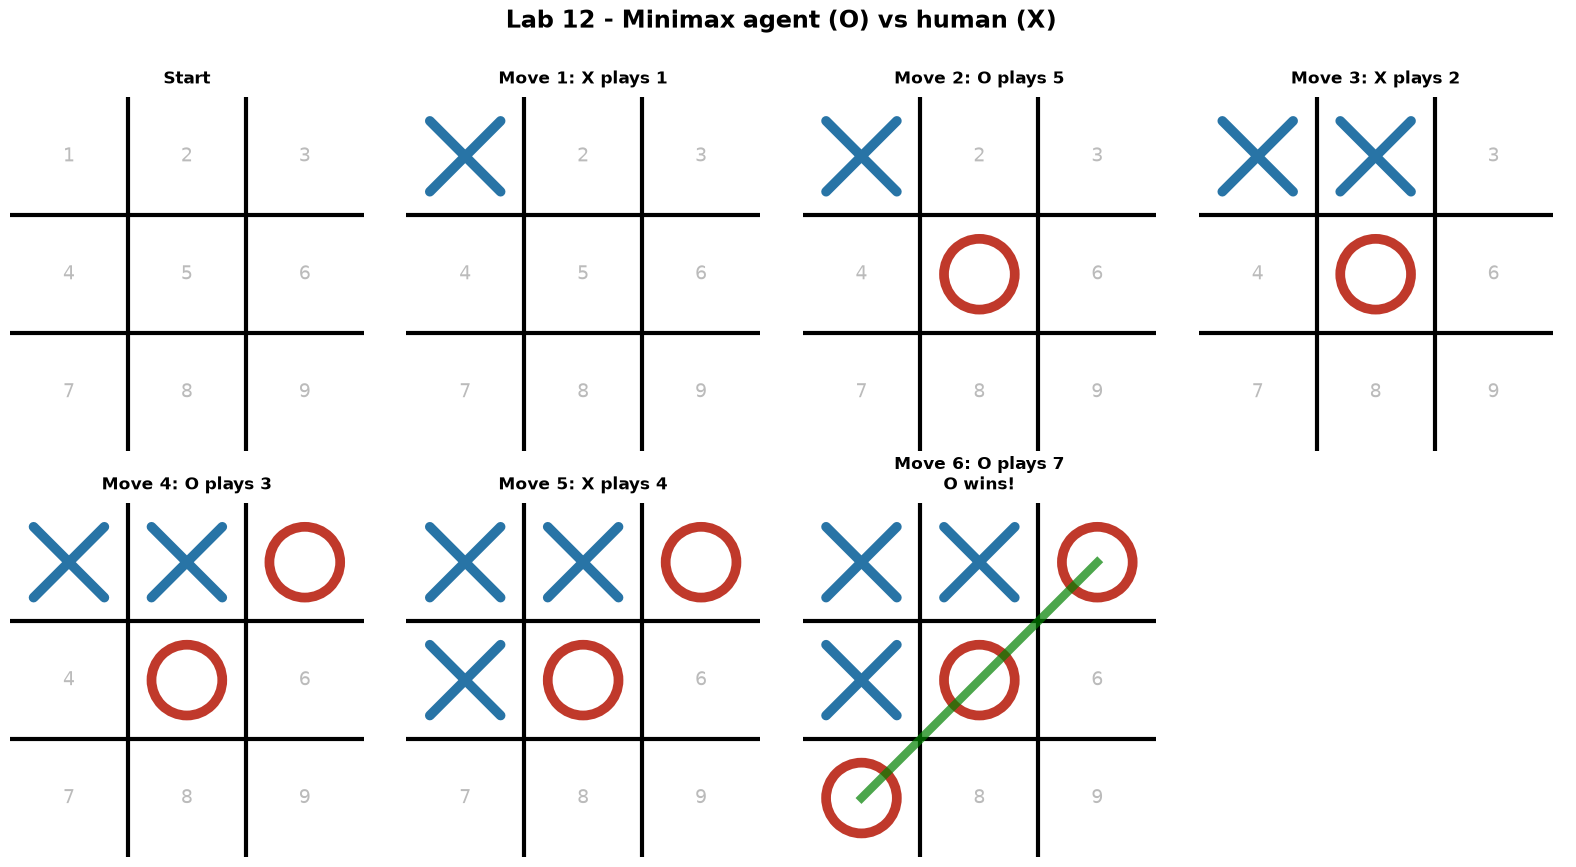

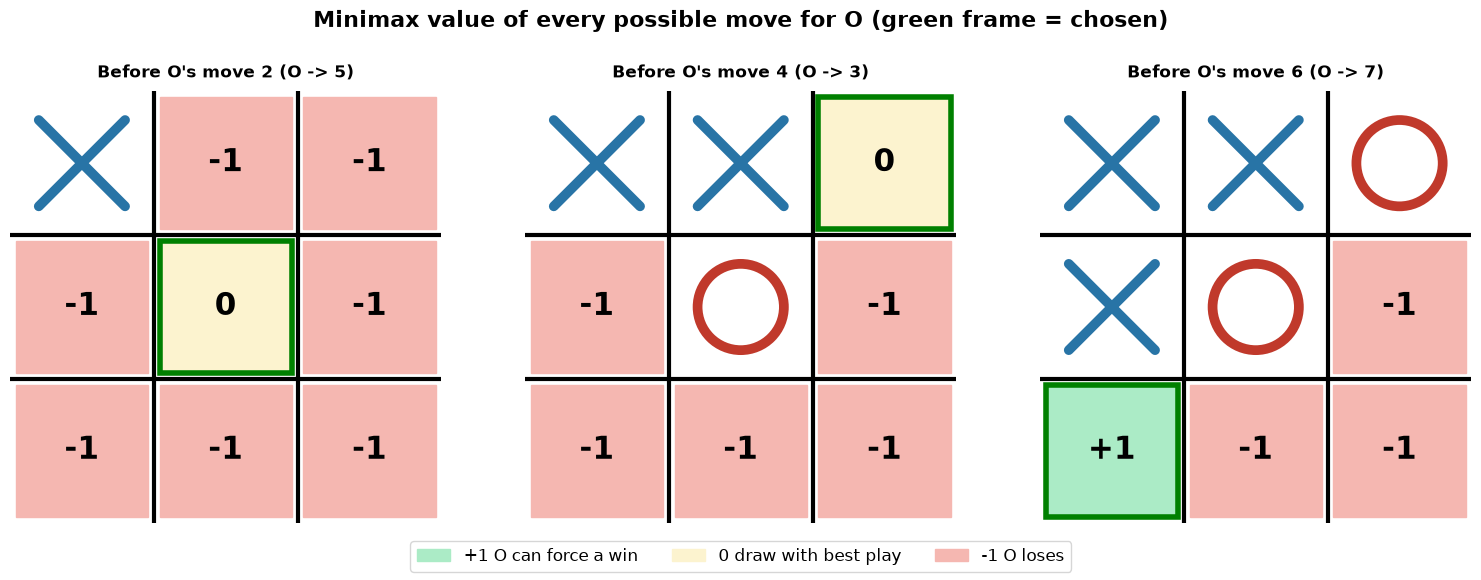


Images saved: lab12_game_output.png, lab12_scores_output.png

Value of the empty board with perfect play = 0 (draw); full tree has 549946 nodes.


In [11]:
demo()

In [12]:
play()

You are X, computer is O. Cells are numbered 1-9:
 1 | 2 | 3
---+---+---
 4 | 5 | 6
---+---+---
 7 | 8 | 9



Your move (1-9):  1


 X |   |  
---+---+---
   |   |  
---+---+---
   |   |  

Computer plays 5 (searched 59704 nodes)
 X |   |  
---+---+---
   | O |  
---+---+---
   |   |  



Your move (1-9):  9


 X |   |  
---+---+---
   | O |  
---+---+---
   |   | X

Computer plays 2 (searched 1052 nodes)
 X | O |  
---+---+---
   | O |  
---+---+---
   |   | X



Your move (1-9):  8


 X | O |  
---+---+---
   | O |  
---+---+---
   | X | X

Computer plays 7 (searched 46 nodes)
 X | O |  
---+---+---
   | O |  
---+---+---
 O | X | X



Your move (1-9):  3


 X | O | X
---+---+---
   | O |  
---+---+---
 O | X | X

Computer plays 6 (searched 4 nodes)
 X | O | X
---+---+---
   | O | O
---+---+---
 O | X | X



Your move (1-9):  4


 X | O | X
---+---+---
 X | O | O
---+---+---
 O | X | X

It's a draw!
